# Window KRR Playground: `temperature_rain_with_missing`

This notebook treats `temperature_rain_with_missing` as its own forecasting problem and uses the
shared window-based kernel ridge regression code in `src/window_krr.py`.

It supports:
- short-term forecasting of `validation \ train` using the `train` split,
- one-block direct test-window forecasting using the `validation` split,
- stitched direct teacher-forced forecasting over the test tail,
- one-shot direct forecasting over the test tail when feasible,
- recursive chunked forecasting from the validation endpoint.

The top parameter cell is meant to be edited freely.

In [23]:
import os
import sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate the KMD_TS repository root from the current working directory.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)
print("GIFT_EVAL:", os.environ["GIFT_EVAL"])

Repo root: /Users/jonghyeonlee/KMD_TS
GIFT_EVAL: /Users/jonghyeonlee/KMD_TS/GiftEval_data


In [24]:
import math
import numpy as np
import matplotlib.pyplot as plt

from gift_eval.data import Dataset
from src.window_krr import (
    KernelConfig,
    WindowKernelRidgeForecaster,
    apply_normalization,
    build_gap_deltas_from_mask,
    build_regular_deltas,
    compute_normalization_stats,
    invert_normalization,
    make_windowed_forecasting_dataset,
    relative_l2_error,
    trim_leading_unobserved_prefix,
)

In [35]:
DATASET_NAME = "temperature_rain_with_missing"
TERM = "short"
TO_UNIVARIATE = False

# Pick the series you want to visualize and evaluate.
SERIES_INDEX = 0

# Keep these conservative by default so large datasets stay interactive.
MAX_SERIES = 200
MAX_WINDOWS_PER_SERIES = 20

CONTEXT_LENGTH = 180
SHORT_HORIZON = None         # defaults to dataset.prediction_length
LONG_HORIZON = None          # defaults to dataset.prediction_length
TRAIN_STRIDE = None          # defaults to SHORT_HORIZON
VALIDATION_STRIDE = None     # defaults to LONG_HORIZON
NORMALIZATION = "none"      # one of: "none", "robust_series", "robust_context"
TRIM_LEADING_UNOBSERVED = False   # useful for left-padded datasets like electricity/*

REPRESENTATION = "masked"    # one of: "masked", "interleaved", "plain"
KERNEL_FAMILY = "rbf"        # one of: rbf, matern25, polynomial, laplace, inverse_quadratic, linear
AMPLITUDE = 1.0
LENGTH_SCALE = 1225.078806
DEGREE = 2
GAMMA = None
COEF0 = 1.0
MASK_DECAY_GAMMA = 0.9      # 1.0 = uniform coordinate weighting; smaller values emphasize recent entries
REGULARIZATION = 0.1

# Delta handling for the interleaved representation.
# "regular" means every step has the same delta.
# "since_last_observed" turns missing stretches into increasing deltas.
DELTA_MODE = "regular"       # one of: "regular", "since_last_observed"
DELTA_STEP = 1.0

# Test-time controls
TEST_WINDOW_INDEX = 0
ROLLING_TEST_WINDOW_LIMIT = None     # set to an integer to cap rolling evaluation windows
PLOT_STITCHED_TEST_TAIL = True       # plot the concatenated direct test-tail forecast
ONE_SHOT_TEST_TAIL = True            # fit a direct model for the whole concatenated test tail when feasible
RECURSIVE_TOTAL_HORIZON = None       # defaults to dataset.windows * dataset.prediction_length
RECURSIVE_CHUNK_LENGTH = 30

# Evaluation scope
EVALUATE_ALL_SERIES = False          # if False, evaluate SERIES_INDEX only
EVAL_SERIES_LIMIT = None             # optional cap when EVALUATE_ALL_SERIES=True
PLOT_FIRST_SERIES_WHEN_AGGREGATING = False
SAME_SERIES_ONLY_BANK = False        # if True, fit each forecast using windows from the same series only

## Kernel Representations

Set `REPRESENTATION` in the parameter cell to:
- `"masked"` for the mask-aware kernel `k((x,m),(x',m'))`
- `"interleaved"` for the observed-only interleaved feature map
  `z=(x_{j_1},Δ_{j_1},...,x_{j_r},Δ_{j_r})`, where `j_1 < ... < j_r` are the observed indices
- `"plain"` for value-only kernels

For interleaved kernels:
- `DELTA_MODE="regular"` uses constant time steps
- `DELTA_MODE="since_last_observed"` increases the delta across missing stretches

Note: internally, interleaved features are stored in padded arrays only so they can
fit in a matrix, but padded coordinates are always masked out of the kernel. They
do not contribute as zero-valued observations.

In [36]:
dataset = Dataset(
    name=DATASET_NAME,
    term=TERM,
    to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)

print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : temperature_rain_with_missing
frequency          : D
prediction_length  : 30
test windows/series: 3
n_raw_series       : 32072
target_dim         : 1


In [37]:
def _nth_item(data_it, index: int):
    for i, item in enumerate(data_it):
        if i == index:
            return item
    raise IndexError(f"Index {index} is out of range.")


def _series_from_entry(entry) -> np.ndarray:
    values = np.asarray(entry["target"], dtype=float).reshape(-1)
    if TRIM_LEADING_UNOBSERVED:
        values, _, _ = trim_leading_unobserved_prefix(values)
    return values


def _get_train_entry(series_index: int):
    return _nth_item(dataset.training_dataset, series_index)


def _get_validation_entry(series_index: int):
    return _nth_item(dataset.validation_dataset, series_index)


def _get_test_pair(series_index: int, window_index: int):
    if window_index < 0 or window_index >= dataset.windows:
        raise IndexError(
            f"window_index={window_index} is out of range for dataset.windows={dataset.windows}."
        )
    flat_index = series_index * dataset.windows + window_index
    test_context = _nth_item(dataset.test_data.input, flat_index)
    test_label = _nth_item(dataset.test_data.label, flat_index)
    return test_context, test_label


def _get_all_test_pairs_for_series(series_index: int, *, limit: int | None = None):
    n_windows = dataset.windows if limit is None else min(int(limit), dataset.windows)
    pairs = []
    for window_index in range(n_windows):
        pairs.append(_get_test_pair(series_index, window_index))
    return pairs


def _get_test_tail(series_index: int, *, limit: int | None = None) -> np.ndarray:
    label_blocks = [
        _series_from_entry(label_entry)
        for _, label_entry in _get_all_test_pairs_for_series(series_index, limit=limit)
    ]
    if not label_blocks:
        return np.empty((0,), dtype=float)
    return np.concatenate(label_blocks)


def _get_validation_plus_test_series(series_index: int, *, limit: int | None = None) -> np.ndarray:
    val = _series_from_entry(_get_validation_entry(series_index))
    test_tail = _get_test_tail(series_index, limit=limit)
    if test_tail.size == 0:
        return val.copy()
    return np.concatenate([val, test_tail])


def _validation_minus_train(series_index: int) -> np.ndarray:
    train = _series_from_entry(_get_train_entry(series_index))
    val = _series_from_entry(_get_validation_entry(series_index))
    return val[len(train):]


def _kernel_config() -> KernelConfig:
    return KernelConfig(
        family=KERNEL_FAMILY,
        amplitude=AMPLITUDE,
        length_scale=LENGTH_SCALE,
        degree=DEGREE,
        gamma=GAMMA,
        coef0=COEF0,
        mask_decay_gamma=MASK_DECAY_GAMMA,
    )


def _build_deltas_from_values(values: np.ndarray) -> np.ndarray:
    observed_mask = np.isfinite(values)
    if DELTA_MODE == "regular":
        return build_regular_deltas(len(values), step=DELTA_STEP)
    if DELTA_MODE == "since_last_observed":
        return build_gap_deltas_from_mask(observed_mask, step=DELTA_STEP)
    raise ValueError(
        f"Unsupported DELTA_MODE={DELTA_MODE}. "
        "Supported modes are 'regular' and 'since_last_observed'."
    )


def _normalization_mode():
    mode = str(NORMALIZATION).lower()
    if mode not in {"none", "robust_series", "robust_context"}:
        raise ValueError(
            f"Unsupported NORMALIZATION={NORMALIZATION}. "
            "Supported modes are 'none', 'robust_series', and 'robust_context'."
        )
    return mode


def _query_normalization_stats(context_values: np.ndarray, *, reference_values: np.ndarray | None = None):
    mode = _normalization_mode()
    context_mask = np.isfinite(context_values)
    if mode == "none":
        return compute_normalization_stats(
            context_values,
            observed_mask=context_mask,
            mode="none",
        )
    if mode == "robust_series":
        reference = context_values if reference_values is None else reference_values
        reference_mask = np.isfinite(reference)
        return compute_normalization_stats(
            reference,
            observed_mask=reference_mask,
            mode="robust_series",
        )
    return compute_normalization_stats(
        context_values,
        observed_mask=context_mask,
        mode="robust_context",
    )


def _normalize_query_context(context_values: np.ndarray, *, reference_values: np.ndarray | None = None):
    stats = _query_normalization_stats(context_values, reference_values=reference_values)
    normalized = apply_normalization(
        context_values,
        stats=stats,
        observed_mask=np.isfinite(context_values),
    )
    return normalized, stats


def _build_window_bank_from_split(
    split_name: str,
    *,
    context_length: int,
    horizon_length: int,
    stride: int | None,
    max_series: int | None,
    max_windows_per_series: int | None,
    only_series_index: int | None = None,
    normalization: str | None = None,
):
    if split_name not in {"train", "validation"}:
        raise ValueError("split_name must be either 'train' or 'validation'.")
    if context_length <= 0:
        raise ValueError("context_length must be positive.")
    if horizon_length <= 0:
        raise ValueError("horizon_length must be positive.")

    entry_iter = dataset.training_dataset if split_name == "train" else dataset.validation_dataset
    stride = horizon_length if stride is None else int(stride)
    if stride <= 0:
        raise ValueError("stride must be positive.")
    bank_normalization = _normalization_mode() if normalization is None else str(normalization).lower()

    contexts = []
    targets = []
    context_masks = []
    target_masks = []
    context_deltas = []
    target_deltas = []
    used_series = 0
    skipped = []

    for series_index, entry in enumerate(entry_iter):
        if only_series_index is not None and series_index != only_series_index:
            continue
        if only_series_index is None and max_series is not None and series_index >= max_series:
            break
        values = _series_from_entry(entry)
        if values.size == 0:
            skipped.append((series_index, "series is empty after trimming leading unobserved prefix"))
            continue
        observed_mask = np.isfinite(values)
        deltas = _build_deltas_from_values(values)
        try:
            windowed = make_windowed_forecasting_dataset(
                values,
                context_length=context_length,
                horizon_length=horizon_length,
                observed_mask=observed_mask,
                deltas=deltas,
                stride=stride,
                max_windows=max_windows_per_series,
                include_last=True,
                drop_all_missing_targets=True,
                normalization=bank_normalization,
            )
        except ValueError as exc:
            skipped.append((series_index, str(exc)))
            continue

        contexts.append(windowed.contexts)
        targets.append(windowed.targets)
        context_masks.append(windowed.context_masks)
        target_masks.append(windowed.target_masks)
        context_deltas.append(windowed.context_deltas)
        target_deltas.append(windowed.target_deltas)
        used_series += 1

    if not contexts:
        raise ValueError(
            f"No valid windows could be built from split '{split_name}'. "
            "Try reducing CONTEXT_LENGTH, LONG_HORIZON/SHORT_HORIZON, or MAX_WINDOWS_PER_SERIES."
        )

    return {
        "contexts": np.vstack(contexts),
        "targets": np.vstack(targets),
        "context_masks": np.vstack(context_masks),
        "target_masks": np.vstack(target_masks),
        "context_deltas": np.vstack(context_deltas),
        "target_deltas": np.vstack(target_deltas),
        "used_series": used_series,
        "n_windows": sum(arr.shape[0] for arr in contexts),
        "skipped": skipped,
    }


def _fit_forecaster_from_split(
    split_name: str,
    *,
    context_length: int,
    horizon_length: int,
    stride: int | None,
    max_series: int | None,
    max_windows_per_series: int | None,
    only_series_index: int | None = None,
    label: str = "Bank",
    verbose: bool = False,
):
    bank = _build_window_bank_from_split(
        split_name,
        context_length=context_length,
        horizon_length=horizon_length,
        stride=stride,
        max_series=max_series,
        max_windows_per_series=max_windows_per_series,
        only_series_index=only_series_index,
    )
    if verbose:
        print(f"{label} bank windows:", bank["n_windows"])
        print(f"{label} bank series :", bank["used_series"])
        print(f"{label} skipped     :", len(bank["skipped"]))

    model = _make_forecaster()
    model.fit(
        bank["contexts"],
        bank["targets"],
        context_masks=bank["context_masks"],
        target_masks=bank["target_masks"],
        context_deltas=bank["context_deltas"],
    )
    return bank, model


def _make_forecaster():
    return WindowKernelRidgeForecaster(
        kernel_config=_kernel_config(),
        representation=REPRESENTATION,
        regularization=REGULARIZATION,
    )


def _plot_forecast(y_true, y_pred, *, title: str, mask=None):
    true_arr = np.asarray(y_true, dtype=float).reshape(-1)
    pred_arr = np.asarray(y_pred, dtype=float).reshape(-1)
    if mask is None:
        obs_mask = np.isfinite(true_arr)
    else:
        obs_mask = np.asarray(mask, dtype=bool).reshape(-1) & np.isfinite(true_arr)

    t = np.arange(1, true_arr.shape[0] + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, true_arr, label="true", linewidth=2)
    plt.plot(t, pred_arr, label="predicted", linewidth=2)
    if not obs_mask.all():
        plt.scatter(t[~obs_mask], np.zeros((~obs_mask).sum()), marker="x", label="missing target")
    plt.title(title)
    plt.xlabel("time index within forecast horizon")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def _evaluation_series_indices():
    if not EVALUATE_ALL_SERIES:
        return [SERIES_INDEX]
    limit = len(dataset.hf_dataset) if EVAL_SERIES_LIMIT is None else min(int(EVAL_SERIES_LIMIT), len(dataset.hf_dataset))
    if limit <= 0:
        raise ValueError("EVAL_SERIES_LIMIT must be positive when provided.")
    return list(range(limit))


def _print_error_summary(name: str, errors: list[float], skipped: list[tuple[int, str]]):
    if not errors:
        raise ValueError(f"No valid evaluation series were available for {name}.")
    arr = np.asarray(errors, dtype=float)
    print(f"{name} evaluated series:", len(errors))
    print(f"{name} skipped series  :", len(skipped))
    print(f"{name} mean relative L2:", float(np.mean(arr)))
    print(f"{name} median relative L2:", float(np.median(arr)))
    print(f"{name} min relative L2 :", float(np.min(arr)))
    print(f"{name} max relative L2 :", float(np.max(arr)))

Selected series index: 0
train length         : 605
validation length    : 635
validation\train len : 30
test windows         : 3
test tail length     : 90
trim leading missing : False
trimmed prefix len   : 0


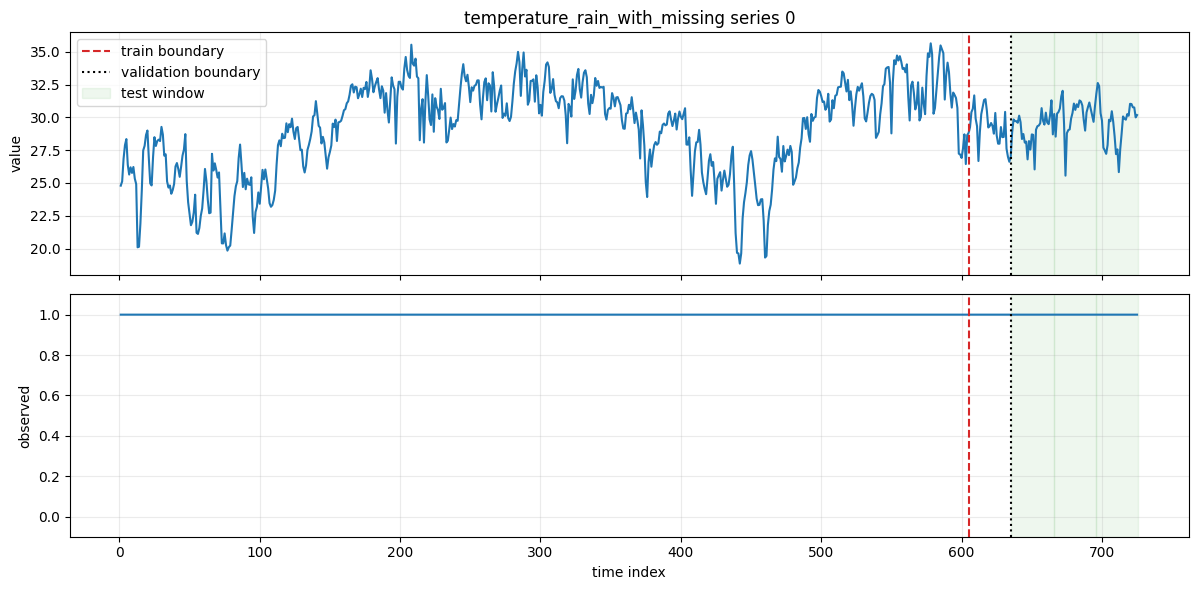

In [38]:
train_entry = _get_train_entry(SERIES_INDEX)
val_entry = _get_validation_entry(SERIES_INDEX)

raw_train_series = np.asarray(train_entry["target"], dtype=float).reshape(-1)
_, _, train_trim_offset = trim_leading_unobserved_prefix(raw_train_series)
train_series = _series_from_entry(train_entry)
val_series = _series_from_entry(val_entry)
val_extra = val_series[len(train_series):]
test_tail = _get_test_tail(SERIES_INDEX)
full_series = _get_validation_plus_test_series(SERIES_INDEX)
full_mask = np.isfinite(full_series).astype(int)

print("Selected series index:", SERIES_INDEX)
print("train length         :", len(train_series))
print("validation length    :", len(val_series))
print("validation\\train len :", len(val_extra))
print("test windows         :", dataset.windows)
print("test tail length     :", len(test_tail))
print("trim leading missing :", TRIM_LEADING_UNOBSERVED)
print("trimmed prefix len   :", train_trim_offset if TRIM_LEADING_UNOBSERVED else 0)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
x_full = np.arange(1, len(full_series) + 1)
axes[0].plot(x_full, full_series, linewidth=1.5)
axes[0].axvline(len(train_series), color="tab:red", linestyle="--", label="train boundary")
axes[0].axvline(len(val_series), color="black", linestyle=":", label="validation boundary")
for window_index in range(dataset.windows):
    start = len(val_series) + window_index * dataset.prediction_length + 1
    end = start + dataset.prediction_length - 1
    axes[0].axvspan(
        start - 0.5,
        end + 0.5,
        color="tab:green",
        alpha=0.08,
        label="test window" if window_index == 0 else None,
    )
axes[0].set_title(f"{DATASET_NAME} series {SERIES_INDEX}")
axes[0].set_ylabel("value")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].step(x_full, full_mask, where="post")
axes[1].axvline(len(train_series), color="tab:red", linestyle="--")
axes[1].axvline(len(val_series), color="black", linestyle=":")
for window_index in range(dataset.windows):
    start = len(val_series) + window_index * dataset.prediction_length + 1
    end = start + dataset.prediction_length - 1
    axes[1].axvspan(start - 0.5, end + 0.5, color="tab:green", alpha=0.08)
axes[1].set_ylabel("observed")
axes[1].set_xlabel("time index")
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Short-Term Forecast: `train -> validation \\ train`

Short-term bank windows: 3000
Short-term bank series : 200
Short-term skipped     : 0


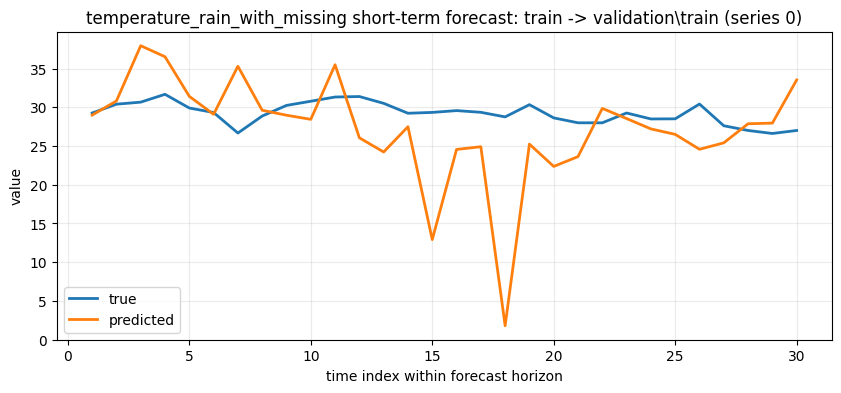

Short-term relative L2: 0.23913377513513726


In [39]:
short_horizon = dataset.prediction_length if SHORT_HORIZON is None else int(SHORT_HORIZON)
if short_horizon <= 0:
    raise ValueError("SHORT_HORIZON must be positive.")

val_extra = _validation_minus_train(SERIES_INDEX)
if not EVALUATE_ALL_SERIES:
    if short_horizon > len(val_extra):
        raise ValueError(
            f"SHORT_HORIZON={short_horizon} exceeds len(validation\\train)={len(val_extra)}. "
            "Reduce SHORT_HORIZON or use a different development target."
        )

    if CONTEXT_LENGTH > len(train_series):
        raise ValueError(
            f"CONTEXT_LENGTH={CONTEXT_LENGTH} exceeds training length {len(train_series)} "
            f"for series {SERIES_INDEX}."
        )

short_model = None
if not SAME_SERIES_ONLY_BANK:
    _, short_model = _fit_forecaster_from_split(
        "train",
        context_length=CONTEXT_LENGTH,
        horizon_length=short_horizon,
        stride=TRAIN_STRIDE,
        max_series=MAX_SERIES,
        max_windows_per_series=MAX_WINDOWS_PER_SERIES,
        label="Short-term",
        verbose=True,
    )

short_errors = []
short_skipped = []
plotted = False
for eval_series_index in _evaluation_series_indices():
    eval_train = _series_from_entry(_get_train_entry(eval_series_index))
    eval_val_extra = _validation_minus_train(eval_series_index)
    if CONTEXT_LENGTH > len(eval_train):
        short_skipped.append((eval_series_index, "context longer than train prefix"))
        continue
    if short_horizon > len(eval_val_extra):
        short_skipped.append((eval_series_index, "short horizon longer than validation\\train"))
        continue

    current_short_model = short_model
    if SAME_SERIES_ONLY_BANK:
        try:
            _, current_short_model = _fit_forecaster_from_split(
                "train",
                context_length=CONTEXT_LENGTH,
                horizon_length=short_horizon,
                stride=TRAIN_STRIDE,
                max_series=None,
                max_windows_per_series=MAX_WINDOWS_PER_SERIES,
                only_series_index=eval_series_index,
                label=f"Short-term series {eval_series_index}",
                verbose=(not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX),
            )
        except ValueError as exc:
            short_skipped.append((eval_series_index, f"same-series short-term bank unavailable: {exc}"))
            continue

    short_query_raw = eval_train[-CONTEXT_LENGTH:]
    short_query, short_stats = _normalize_query_context(
        short_query_raw,
        reference_values=eval_train,
    )
    short_pred_norm = current_short_model.forecast(
        short_query,
        strategy="direct",
        total_horizon=short_horizon,
        query_masks=np.isfinite(short_query_raw),
        query_deltas=_build_deltas_from_values(short_query_raw),
    ).reshape(-1)
    short_pred = invert_normalization(short_pred_norm, stats=short_stats)

    short_true = eval_val_extra[:short_horizon]
    short_mask = np.isfinite(short_true)
    if not short_mask.any():
        short_skipped.append((eval_series_index, "validation\\train target is entirely missing"))
        continue
    short_rel_l2 = relative_l2_error(short_true, short_pred, mask=short_mask)
    short_errors.append(short_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
    )
    if should_plot:
        _plot_forecast(
            short_true,
            short_pred,
            title=f"{DATASET_NAME} short-term forecast: train -> validation\\train (series {eval_series_index})",
            mask=short_mask,
        )
        plotted = True

if EVALUATE_ALL_SERIES:
    _print_error_summary("Short-term", short_errors, short_skipped)
else:
    if not short_errors:
        raise ValueError(
            f"Series {SERIES_INDEX} has no observed entries in validation\\train for the chosen SHORT_HORIZON={short_horizon}. "
            "Choose a different SERIES_INDEX or use EVALUATE_ALL_SERIES=True."
        )
    print("Short-term relative L2:", short_errors[0])

## Long-Term Setup

In [40]:
selected_val_series = _series_from_entry(_get_validation_entry(SERIES_INDEX))
long_horizon = dataset.prediction_length if LONG_HORIZON is None else int(LONG_HORIZON)
if long_horizon <= 0:
    raise ValueError("LONG_HORIZON must be positive.")
if not EVALUATE_ALL_SERIES and CONTEXT_LENGTH > len(selected_val_series):
    raise ValueError(
        f"CONTEXT_LENGTH={CONTEXT_LENGTH} exceeds validation length {len(selected_val_series)} "
        f"for series {SERIES_INDEX}."
    )

one_shot_window_count = dataset.windows if ROLLING_TEST_WINDOW_LIMIT is None else min(int(ROLLING_TEST_WINDOW_LIMIT), dataset.windows)
one_shot_horizon = one_shot_window_count * dataset.prediction_length
long_model = None
one_shot_model = None
one_shot_bank_error = None
if not SAME_SERIES_ONLY_BANK:
    _, long_model = _fit_forecaster_from_split(
        "validation",
        context_length=CONTEXT_LENGTH,
        horizon_length=long_horizon,
        stride=VALIDATION_STRIDE,
        max_series=MAX_SERIES,
        max_windows_per_series=MAX_WINDOWS_PER_SERIES,
        label="Long-term",
        verbose=True,
    )
    if ONE_SHOT_TEST_TAIL:
        try:
            _, one_shot_model = _fit_forecaster_from_split(
                "validation",
                context_length=CONTEXT_LENGTH,
                horizon_length=one_shot_horizon,
                stride=VALIDATION_STRIDE,
                max_series=MAX_SERIES,
                max_windows_per_series=MAX_WINDOWS_PER_SERIES,
                label="One-shot",
                verbose=True,
            )
        except ValueError as exc:
            one_shot_bank_error = str(exc)
            print("One-shot test-tail model unavailable:", one_shot_bank_error)
else:
    print("Using same-series-only bank: long-term models will be refit per evaluated series.")

def _get_long_models(eval_series_index: int, *, verbose: bool = False):
    current_long_model = long_model
    current_one_shot_model = one_shot_model
    current_one_shot_bank_error = one_shot_bank_error
    if SAME_SERIES_ONLY_BANK:
        _, current_long_model = _fit_forecaster_from_split(
            "validation",
            context_length=CONTEXT_LENGTH,
            horizon_length=long_horizon,
            stride=VALIDATION_STRIDE,
            max_series=None,
            max_windows_per_series=MAX_WINDOWS_PER_SERIES,
            only_series_index=eval_series_index,
            label=f"Long-term series {eval_series_index}",
            verbose=verbose,
        )
        current_one_shot_model = None
        current_one_shot_bank_error = None
        if ONE_SHOT_TEST_TAIL:
            try:
                _, current_one_shot_model = _fit_forecaster_from_split(
                    "validation",
                    context_length=CONTEXT_LENGTH,
                    horizon_length=one_shot_horizon,
                    stride=VALIDATION_STRIDE,
                    max_series=None,
                    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
                    only_series_index=eval_series_index,
                    label=f"One-shot series {eval_series_index}",
                    verbose=False,
                )
            except ValueError as exc:
                current_one_shot_bank_error = str(exc)
    return current_long_model, current_one_shot_model, current_one_shot_bank_error

print("Selected test window index:", TEST_WINDOW_INDEX)
print("Long horizon            :", long_horizon)
print("One-shot horizon        :", one_shot_horizon)

Long-term bank windows: 3200
Long-term bank series : 200
Long-term skipped     : 0
One-shot bank windows: 1200
One-shot bank series : 200
One-shot skipped     : 0
Selected test window index: 0
Long horizon            : 30
One-shot horizon        : 90


## Direct Forecast: One Test Window

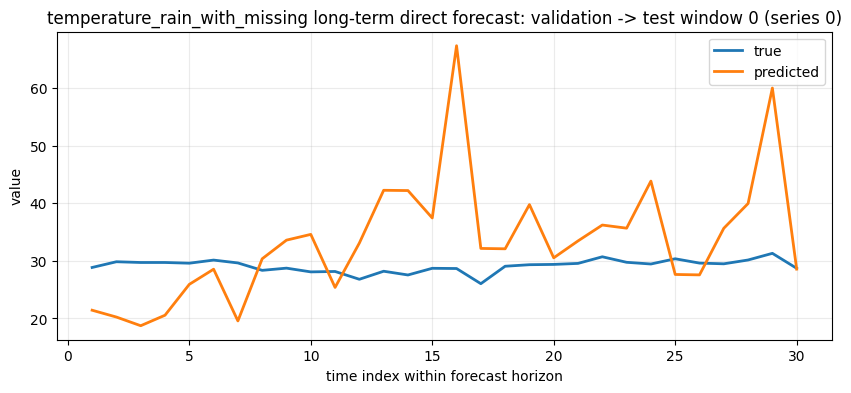

Long-term relative L2: 0.3954523887337253


In [41]:
direct_errors = []
direct_skipped = []
plotted = False

for eval_series_index in _evaluation_series_indices():
    try:
        current_long_model, _, _ = _get_long_models(
            eval_series_index,
            verbose=(not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX),
        )
    except ValueError as exc:
        direct_skipped.append((eval_series_index, f"same-series long-term bank unavailable: {exc}"))
        continue

    test_context_entry, test_label_entry = _get_test_pair(eval_series_index, TEST_WINDOW_INDEX)
    test_context = _series_from_entry(test_context_entry)
    test_label = _series_from_entry(test_label_entry)
    if CONTEXT_LENGTH > len(test_context):
        direct_skipped.append((eval_series_index, "context longer than selected test context"))
        continue
    if long_horizon > len(test_label):
        direct_skipped.append((eval_series_index, "long horizon longer than selected test label"))
        continue

    long_query_raw = test_context[-CONTEXT_LENGTH:]
    long_query, long_stats = _normalize_query_context(
        long_query_raw,
        reference_values=test_context,
    )
    long_pred_norm = current_long_model.forecast(
        long_query,
        strategy="direct",
        total_horizon=long_horizon,
        query_masks=np.isfinite(long_query_raw),
        query_deltas=_build_deltas_from_values(long_query_raw),
    ).reshape(-1)
    long_pred = invert_normalization(long_pred_norm, stats=long_stats)

    long_true = test_label[:long_horizon]
    long_mask = np.isfinite(long_true)
    if not long_mask.any():
        direct_skipped.append((eval_series_index, "selected test label is entirely missing"))
        continue
    direct_rel_l2 = relative_l2_error(long_true, long_pred, mask=long_mask)
    direct_errors.append(direct_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
    )
    if should_plot:
        _plot_forecast(
            long_true,
            long_pred,
            title=f"{DATASET_NAME} long-term direct forecast: validation -> test window {TEST_WINDOW_INDEX} (series {eval_series_index})",
            mask=long_mask,
        )
        plotted = True

if EVALUATE_ALL_SERIES:
    _print_error_summary("Long-term direct", direct_errors, direct_skipped)
else:
    if not direct_errors:
        raise ValueError(
            f"Series {SERIES_INDEX} has no observed entries in the selected test label for TEST_WINDOW_INDEX={TEST_WINDOW_INDEX} "
            f"and LONG_HORIZON={long_horizon}. Choose a different SERIES_INDEX or use EVALUATE_ALL_SERIES=True."
        )
    print("Long-term relative L2:", direct_errors[0])

## Teacher-Forced Forecast: Stitched Direct Test Tail

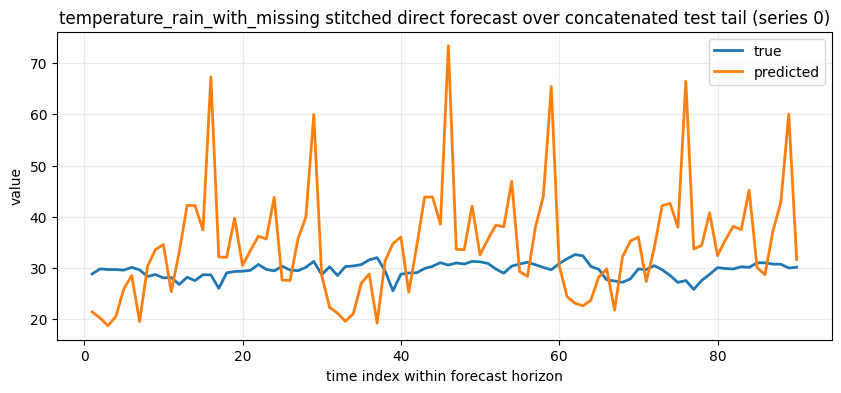

Teacher-forced per-window relative L2 errors:
  window 0: 0.3954523887337253
  window 1: 0.43080807365247936
  window 2: 0.39903218899123977
Teacher-forced mean over windows: 0.4084308837924815
Stitched direct tail L2: 0.409183038482683
Rolling test windows evaluated: 3
Rolling mean relative L2      : 0.4084308837924815


In [42]:
stitched_errors = []
stitched_skipped = []
rolling_means = []
rolling_skipped = []
all_window_errors = []
selected_window_errors = None
plotted = False

for eval_series_index in _evaluation_series_indices():
    try:
        current_long_model, _, _ = _get_long_models(
            eval_series_index,
            verbose=(not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX),
        )
    except ValueError as exc:
        stitched_skipped.append((eval_series_index, f"same-series long-term bank unavailable: {exc}"))
        rolling_skipped.append((eval_series_index, f"same-series long-term bank unavailable: {exc}"))
        continue

    all_pairs = _get_all_test_pairs_for_series(eval_series_index, limit=ROLLING_TEST_WINDOW_LIMIT)
    per_series_rolling = []
    stitched_truth_blocks = []
    stitched_pred_blocks = []
    for _, (ctx_entry, lbl_entry) in enumerate(all_pairs):
        ctx = _series_from_entry(ctx_entry)
        lbl = _series_from_entry(lbl_entry)
        if CONTEXT_LENGTH > len(ctx) or long_horizon > len(lbl):
            continue
        ctx_query_raw = ctx[-CONTEXT_LENGTH:]
        ctx_query, ctx_stats = _normalize_query_context(
            ctx_query_raw,
            reference_values=ctx,
        )
        pred_norm = current_long_model.forecast(
            ctx_query,
            strategy="direct",
            total_horizon=long_horizon,
            query_masks=np.isfinite(ctx_query_raw),
            query_deltas=_build_deltas_from_values(ctx_query_raw),
        ).reshape(-1)
        pred = invert_normalization(pred_norm, stats=ctx_stats)
        truth = lbl[:long_horizon]
        truth_mask = np.isfinite(truth)
        if not truth_mask.any():
            continue
        window_rel_l2 = relative_l2_error(truth, pred, mask=truth_mask)
        per_series_rolling.append(window_rel_l2)
        all_window_errors.append(window_rel_l2)
        stitched_truth_blocks.append(truth)
        stitched_pred_blocks.append(pred)

    if per_series_rolling:
        rolling_means.append(float(np.mean(per_series_rolling)))
        if not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX:
            selected_window_errors = list(per_series_rolling)
    else:
        rolling_skipped.append((eval_series_index, "no valid rolling test windows"))

    if stitched_truth_blocks:
        stitched_true = np.concatenate(stitched_truth_blocks)
        stitched_pred = np.concatenate(stitched_pred_blocks)
        stitched_mask = np.isfinite(stitched_true)
        stitched_errors.append(relative_l2_error(stitched_true, stitched_pred, mask=stitched_mask))

        should_plot = PLOT_STITCHED_TEST_TAIL and (
            (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
                EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
            )
        )
        if should_plot:
            _plot_forecast(
                stitched_true,
                stitched_pred,
                title=f"{DATASET_NAME} stitched direct forecast over concatenated test tail (series {eval_series_index})",
                mask=stitched_mask,
            )
            plotted = True
    else:
        stitched_skipped.append((eval_series_index, "no valid stitched test-tail blocks"))

if EVALUATE_ALL_SERIES:
    if all_window_errors:
        window_arr = np.asarray(all_window_errors, dtype=float)
        print("Teacher-forced per-window evaluations:", len(window_arr))
        print("Teacher-forced per-window mean relative L2:", float(np.mean(window_arr)))
        print("Teacher-forced per-window median relative L2:", float(np.median(window_arr)))
        print("Teacher-forced per-window min relative L2:", float(np.min(window_arr)))
        print("Teacher-forced per-window max relative L2:", float(np.max(window_arr)))
    else:
        print("No valid teacher-forced per-window forecasts were available.")
    if stitched_errors:
        _print_error_summary("Long-term stitched-tail direct", stitched_errors, stitched_skipped)
    else:
        print("No stitched direct test-tail forecasts could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
    if rolling_means:
        _print_error_summary("Long-term rolling-mean", rolling_means, rolling_skipped)
    else:
        print("No rolling test windows could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
else:
    if selected_window_errors:
        print("Teacher-forced per-window relative L2 errors:")
        for window_index, window_error in enumerate(selected_window_errors):
            print(f"  window {window_index}: {window_error}")
        print("Teacher-forced mean over windows:", float(np.mean(np.asarray(selected_window_errors, dtype=float))))
    else:
        print("No valid teacher-forced per-window forecasts were available for the selected series.")
    if stitched_errors:
        print("Stitched direct tail L2:", stitched_errors[0])
    else:
        print("No stitched direct test-tail forecast could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
    if rolling_means:
        print("Rolling test windows evaluated:", len(_get_all_test_pairs_for_series(SERIES_INDEX, limit=ROLLING_TEST_WINDOW_LIMIT)))
        print("Rolling mean relative L2      :", rolling_means[0])
    else:
        print("No rolling test windows could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")

## One-Shot Direct Forecast: Full Test Tail

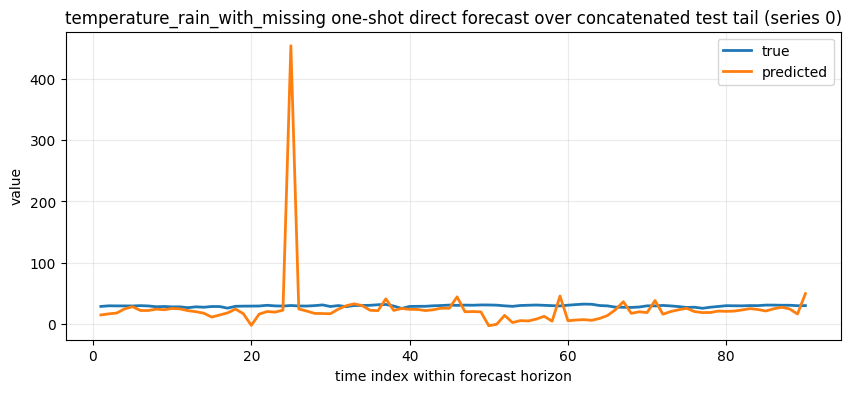

One-shot direct tail L2: 1.57267999840423


In [43]:
if not ONE_SHOT_TEST_TAIL:
    print("ONE_SHOT_TEST_TAIL is False; skipping one-shot evaluation cell.")
else:
    one_shot_errors = []
    one_shot_skipped = []
    plotted = False

    for eval_series_index in _evaluation_series_indices():
        try:
            _, current_one_shot_model, current_one_shot_bank_error = _get_long_models(
                eval_series_index,
                verbose=(not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX),
            )
        except ValueError as exc:
            one_shot_skipped.append((eval_series_index, f"same-series long-term bank unavailable: {exc}"))
            continue

        if current_one_shot_model is None:
            one_shot_skipped.append((eval_series_index, current_one_shot_bank_error or "one-shot model unavailable"))
            continue

        one_shot_val_series = _series_from_entry(_get_validation_entry(eval_series_index))
        one_shot_true = _get_test_tail(eval_series_index, limit=ROLLING_TEST_WINDOW_LIMIT)
        one_shot_mask = np.isfinite(one_shot_true)
        if CONTEXT_LENGTH > len(one_shot_val_series):
            one_shot_skipped.append((eval_series_index, "context longer than validation prefix for one-shot forecast"))
            continue
        if len(one_shot_true) < one_shot_horizon:
            one_shot_skipped.append((eval_series_index, "one-shot tail shorter than expected horizon"))
            continue
        if not one_shot_mask.any():
            one_shot_skipped.append((eval_series_index, "one-shot test tail is entirely missing"))
            continue

        one_shot_query_raw = one_shot_val_series[-CONTEXT_LENGTH:]
        one_shot_query, one_shot_stats = _normalize_query_context(
            one_shot_query_raw,
            reference_values=one_shot_val_series,
        )
        one_shot_pred_norm = current_one_shot_model.forecast(
            one_shot_query,
            strategy="direct",
            total_horizon=one_shot_horizon,
            query_masks=np.isfinite(one_shot_query_raw),
            query_deltas=_build_deltas_from_values(one_shot_query_raw),
        ).reshape(-1)
        one_shot_pred = invert_normalization(one_shot_pred_norm, stats=one_shot_stats)
        one_shot_errors.append(relative_l2_error(one_shot_true[:one_shot_horizon], one_shot_pred, mask=one_shot_mask[:one_shot_horizon]))

        should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
            EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
        )
        if should_plot:
            _plot_forecast(
                one_shot_true[:one_shot_horizon],
                one_shot_pred,
                title=f"{DATASET_NAME} one-shot direct forecast over concatenated test tail (series {eval_series_index})",
                mask=one_shot_mask[:one_shot_horizon],
            )
            plotted = True

    if EVALUATE_ALL_SERIES:
        if one_shot_errors:
            _print_error_summary("Long-term one-shot direct", one_shot_errors, one_shot_skipped)
        else:
            print("No one-shot direct test-tail forecasts could be evaluated with the current CONTEXT_LENGTH/one-shot horizon.")
    else:
        if one_shot_errors:
            print("One-shot direct tail L2:", one_shot_errors[0])
        else:
            first_reason = one_shot_skipped[0][1] if one_shot_skipped else "one-shot horizon unavailable"
            print("One-shot direct tail unavailable:", first_reason)

## Recursive Chunked Forecast from the Validation Endpoint

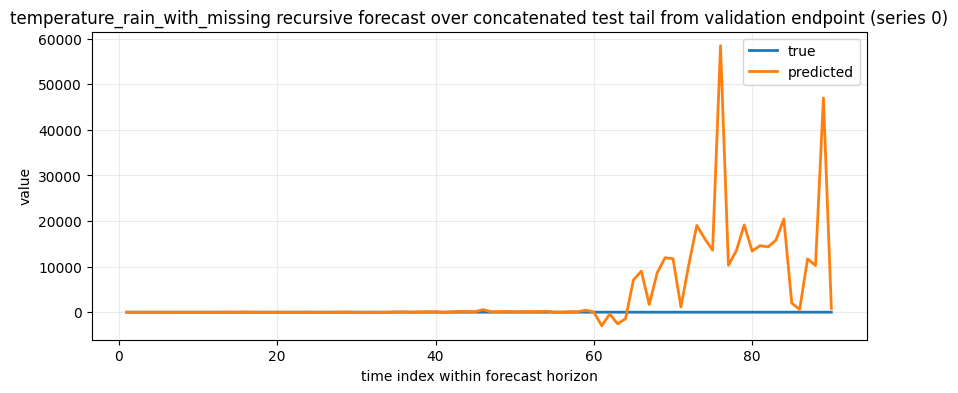

Recursive chunk length: 30
Recursive relative L2  : 341.15796516291664


In [44]:
recursive_chunk_length = long_horizon if RECURSIVE_CHUNK_LENGTH is None else int(RECURSIVE_CHUNK_LENGTH)
if recursive_chunk_length <= 0:
    raise ValueError("RECURSIVE_CHUNK_LENGTH must be positive.")
if recursive_chunk_length > long_horizon:
    raise ValueError(
        f"RECURSIVE_CHUNK_LENGTH={recursive_chunk_length} exceeds LONG_HORIZON={long_horizon}."
    )

recursive_errors = []
recursive_skipped = []
plotted = False

for eval_series_index in _evaluation_series_indices():
    try:
        current_long_model, _, _ = _get_long_models(
            eval_series_index,
            verbose=(not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX),
        )
    except ValueError as exc:
        recursive_skipped.append((eval_series_index, f"same-series recursive bank unavailable: {exc}"))
        continue

    eval_val_series = _series_from_entry(_get_validation_entry(eval_series_index))
    if CONTEXT_LENGTH > len(eval_val_series):
        recursive_skipped.append((eval_series_index, "context longer than validation prefix"))
        continue

    recursive_truth = _get_test_tail(eval_series_index)
    recursive_mask = np.isfinite(recursive_truth)

    recursive_total_horizon = len(recursive_truth) if RECURSIVE_TOTAL_HORIZON is None else int(RECURSIVE_TOTAL_HORIZON)
    if recursive_total_horizon <= 0:
        raise ValueError("RECURSIVE_TOTAL_HORIZON must be positive.")
    recursive_total_horizon = min(recursive_total_horizon, len(recursive_truth))

    recursive_query_raw = eval_val_series[-CONTEXT_LENGTH:]
    recursive_query, recursive_stats = _normalize_query_context(
        recursive_query_raw,
        reference_values=eval_val_series,
    )
    recursive_pred_norm = current_long_model.forecast(
        recursive_query,
        strategy="chunked",
        total_horizon=recursive_total_horizon,
        chunk_length=recursive_chunk_length,
        query_masks=np.isfinite(recursive_query_raw),
        query_deltas=_build_deltas_from_values(recursive_query_raw),
        future_deltas=np.full((1, recursive_total_horizon), DELTA_STEP, dtype=float),
    ).reshape(-1)
    recursive_pred = invert_normalization(recursive_pred_norm, stats=recursive_stats)

    recursive_true = recursive_truth[:recursive_total_horizon]
    recursive_true_mask = recursive_mask[:recursive_total_horizon]
    if not recursive_true_mask.any():
        recursive_skipped.append((eval_series_index, "recursive test tail is entirely missing"))
        continue
    recursive_rel_l2 = relative_l2_error(recursive_true, recursive_pred, mask=recursive_true_mask)
    recursive_errors.append(recursive_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
    )
    if should_plot:
        _plot_forecast(
            recursive_true,
            recursive_pred,
            title=f"{DATASET_NAME} recursive forecast over concatenated test tail from validation endpoint (series {eval_series_index})",
            mask=recursive_true_mask,
        )
        plotted = True

print("Recursive chunk length:", recursive_chunk_length)
if EVALUATE_ALL_SERIES:
    _print_error_summary("Recursive", recursive_errors, recursive_skipped)
else:
    if not recursive_errors:
        raise ValueError(
            f"Series {SERIES_INDEX} has no observed entries in the recursive test tail for RECURSIVE_TOTAL_HORIZON={recursive_total_horizon}. "
            "Choose a different SERIES_INDEX or use EVALUATE_ALL_SERIES=True."
        )
    print("Recursive relative L2  :", recursive_errors[0])